Import dependancies

In [1]:
import math
import duckdb
import pandas as pd
from processing.core import get_bucket
import matplotlib.pyplot as plt

Load the dataset

In [4]:
conn = duckdb.connect("../storage/database/leagues/England.ddb", read_only=True)
table_name = "39-2025-points-l3"
df = conn.execute(f"SELECT * FROM '{table_name}'").df()
df[["home_team", "away_team", "home_goals", "away_goals", "points_diff_bucket_last3","points_per_match_diff_bucket_last3"]]

,home_team,away_team,home_goals,away_goals,points_diff_bucket_last3,points_per_match_diff_bucket_last3
0,Liverpool,Bournemouth,4,2,0,0
1,Aston Villa,Newcastle,0,0,0,0
2,Brighton,Fulham,1,1,0,0
3,Sunderland,West Ham,3,0,0,0
4,Tottenham,Burnley,3,0,0,0
...,...,...,...,...,...,...
375,Manchester City,Aston Villa,1,2,1,1
376,Nottingham Forest,Bournemouth,1,1,-1,-1
377,Sunderland,Chelsea,2,1,1,0
378,Tottenham,Everton,1,0,1,1


Build results

In [5]:
df["result"] = "draw"

df.loc[df["home_goals"] > df["away_goals"], "result"] = "home_win"
df.loc[df["home_goals"] < df["away_goals"], "result"] = "away_win"

Define the PPM bucket thresholds

In [15]:
df["ppm_condition"] = False

df.loc[
    (df["result"] == "home_win") &
    (df["points_diff_bucket_last3"] > 1),
    "ppm_condition"
] = True

df.loc[
    (df["result"] == "draw") &
    (df["points_diff_bucket_last3"].between(-1, 1)),
    "ppm_condition"
] = True

df.loc[
    (df["result"] == "away_win") &
    (df["points_diff_bucket_last3"] < -1),
    "ppm_condition"
] = True

Do a summary

In [17]:
summary = (
    df.groupby("result")
      .agg(
          total_matches=("result", "size"),
          matching_matches=("ppm_condition", "sum")
      )
)

summary["percentage"] = (
    summary["matching_matches"] /
    summary["total_matches"] * 100
)

summary

,total_matches,matching_matches,percentage
result,,,
away_win,114,26,22.807018
draw,104,67,64.423077
home_win,162,26,16.049383


Overall Percentage

In [18]:
overall_matches = len(df)
overall_matching = df["ppm_condition"].sum()

overall_percentage = overall_matching / overall_matches * 100

print(f"Matches satisfying the PPM condition: {overall_matching:,}")
print(f"Total matches: {overall_matches:,}")
print(f"Overall percentage: {overall_percentage:.2f}%")

Matches satisfying the PPM condition: 119
Total matches: 380
Overall percentage: 31.32%


Plot the pie chart

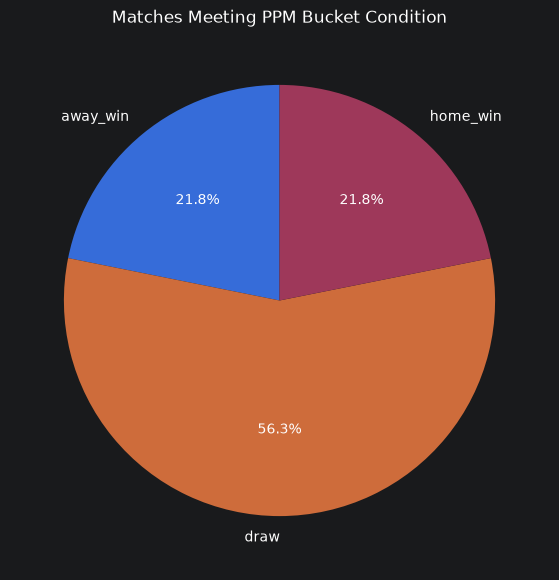

In [19]:
plt.figure(figsize=(7, 7))

plt.pie(
    summary["matching_matches"],
    labels=summary.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Matches Meeting PPM Bucket Condition")
plt.show()

Bucket distribution chart

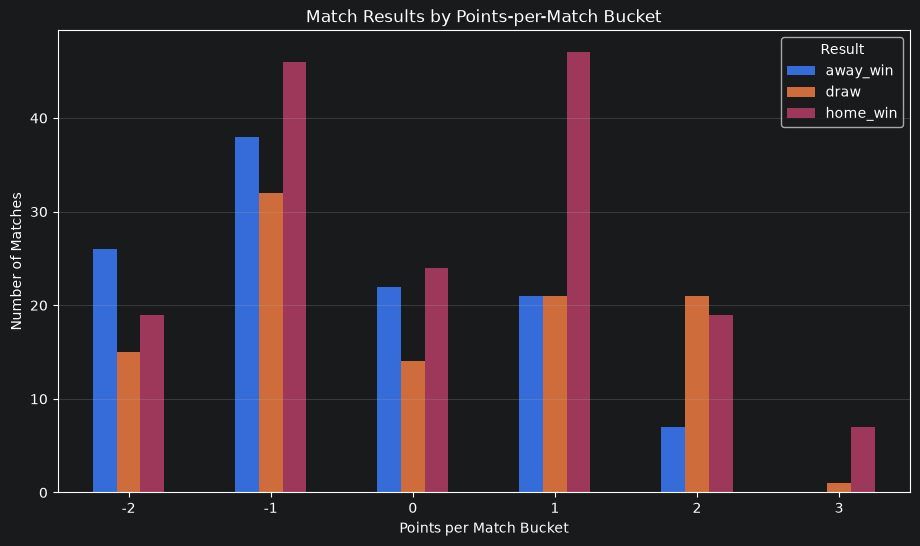

In [20]:
bucket_result = pd.crosstab(
    df["points_diff_bucket_last3"],
    df["result"]
)

bucket_result.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Match Results by Points-per-Match Bucket")
plt.xlabel("Points per Match Bucket")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.legend(title="Result")
plt.grid(axis="y", alpha=0.3)
plt.show()